<a href="https://colab.research.google.com/github/Abhishek1234563/-Robust-Multistatic-Target-Localization-/blob/main/Rotalo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.optimize import least_squares

np.random.seed(42)

# Paper simulation parameters
x_true = np.array([-5.0, 5.0, 10.0])
tx = np.array([30.0, -15.0, 40.0])

M = 5
K = 200

alpha = 0.05
epsilon = 1e-6
max_iter = 300

sigma2_true = 1.0
outlier_percentage = 0.10

print("Target:", x_true)
print("Transmitter:", tx)
print("M =", M)
print("K =", K)

Target: [-5.  5. 10.]
Transmitter: [ 30. -15.  40.]
M = 5
K = 200


In [ ]:
def random_points_on_sphere(n, radius=50.0):
    points = np.random.randn(n, 3)
    points /= np.linalg.norm(points, axis=1, keepdims=True)
    points *= radius
    return points


rx = random_points_on_sphere(M, radius=50.0)

print("Receiver positions:")
print(rx)

Receiver positions:
[[ 30.00010229  -8.35076503  39.11851973]
 [ 48.85856632  -7.51160467  -7.51107799]
 [ 43.44484717  21.11247084 -12.91544923]
 [ 31.83758088 -27.19348476 -27.32915715]
 [  4.67581864 -36.97333214 -33.33330813]]


In [ ]:
def bistatic_ranges(x, tx, rx):
    tx_dist = np.linalg.norm(x - tx)
    rx_dist = np.linalg.norm(x - rx, axis=1)

    return tx_dist + rx_dist

In [ ]:
true_ranges = bistatic_ranges(x_true, tx, rx)

print("True bistatic ranges:")
print(true_ranges)

True bistatic ranges:
[ 97.69554    108.24871663 106.2103712  111.78712099 111.34894987]


In [ ]:
def generate_measurements(x_true, tx, rx, K, sigma2):
    true_ranges = bistatic_ranges(x_true, tx, rx)

    noise = np.random.normal(
        0,
        np.sqrt(sigma2),
        size=(K, len(rx))
    )

    D = true_ranges[None, :] + noise

    return D

In [ ]:
def add_outliers(D, percentage=0.10, magnitude=10.0):
    D_corrupted = D.copy()

    total = D.size
    num_outliers = int(percentage * total)

    indices = np.random.choice(
        total,
        size=num_outliers,
        replace=False
    )

    mask = np.zeros(total, dtype=bool)
    mask[indices] = True
    mask = mask.reshape(D.shape)

    signs = np.random.choice(
        [-1.0, 1.0],
        size=num_outliers
    )

    D_corrupted.flat[indices] += magnitude * signs

    return D_corrupted, mask

Generating our dataset


In [ ]:
D_clean = generate_measurements(
    x_true,
    tx,
    rx,
    K,
    sigma2_true
)

D, true_outlier_mask = add_outliers(
    D_clean,
    percentage=outlier_percentage,
    magnitude=10.0
)

print("Measurement shape:", D.shape)
print("Total measurements:", D.size)
print("Artificial outliers:", np.sum(true_outlier_mask))

Measurement shape: (200, 5)
Total measurements: 1000
Artificial outliers: 100


In [ ]:
def update_sigma2(D, x, tx, rx, b):
    predicted = bistatic_ranges(x, tx, rx)

    residual = D - predicted[None, :]

    sigma2 = np.sum(
        b * residual**2
    ) / D.size

    return max(sigma2, 1e-12)

Test statistic

In [ ]:
def calculate_test_statistics(D, x, tx, rx, sigma2):
    predicted = bistatic_ranges(x, tx, rx)

    residual = D - predicted[None, :]

    return residual**2 / max(sigma2, 1e-12)

In [ ]:
def update_target_fast(D, x, tx, rx, b, sigma2):

    eps = 1e-12

    # -----------------------------------------
    # Transmitter
    # -----------------------------------------
    tx_vec = x - tx
    tx_dist = max(np.linalg.norm(tx_vec), eps)

    s = tx_vec / tx_dist

    # -----------------------------------------
    # Receivers
    # -----------------------------------------
    rx_vec = x - rx
    rx_dist = np.linalg.norm(rx_vec, axis=1)
    rx_dist = np.maximum(rx_dist, eps)

    z = rx_vec / rx_dist[:, None]

    # Exact definitions from paper
    h = tx_dist / rx_dist
    g = rx_dist / tx_dist

    # -----------------------------------------
    # Eq. (16)
    # -----------------------------------------

    weight = b / sigma2

    # Shape:
    # D              -> (K, M)
    # s + z           -> (M, 3)
    # result          -> (K, M, 3)

    A = (
        D[:, :, None] * (s[None, None, :] + z[None, :, :])
        + (1.0 + g)[None, :, None] * tx[None, None, :]
        + (1.0 + h)[None, :, None] * rx[None, :, :]
    )

    numerator = np.sum(
        weight[:, :, None] * A,
        axis=(0, 1)
    )

    denominator = np.sum(
        weight *
        (
            2.0
            + h[None, :]
            + g[None, :]
        )
    )

    if denominator < eps:
        return x.copy()

    return numerator / denominator

In [ ]:
def initialize_target_wls(D, tx, rx):

    d_avg = np.mean(D, axis=0)

    def residual(x):
        predicted = bistatic_ranges(x, tx, rx)
        return predicted - d_avg

    x_start = np.mean(rx, axis=0)

    result = least_squares(
        residual,
        x_start,
        method="trf"
    )

    return result.x

In [ ]:
def initialize_outliers(D, x0, tx, rx):

    predicted = bistatic_ranges(x0, tx, rx)

    residual = D - predicted[None, :]

    abs_residual = np.abs(residual)

    center = np.median(abs_residual)

    mad = np.median(
        np.abs(abs_residual - center)
    )

    if mad < 1e-12:
        return np.ones_like(D)

    threshold = center + 3.0 * 1.4826 * mad

    b0 = (abs_residual <= threshold).astype(float)

    return b0

In [ ]:
def solve_outlier_optimization(T, alpha=0.05):

    T_flat = T.ravel()

    N = len(T_flat)

    # Sort T in descending order
    order = np.argsort(T_flat)[::-1]

    T_sorted = T_flat[order]

    # eta_j from Eq. (8)
    j = np.arange(1, N + 1)

    eta = chi2.ppf(
        1.0 - alpha * j / N,
        df=1
    )

    # Eq. (19)
    prefix_T = np.cumsum(T_sorted)

    total_T = prefix_T[-1]

    penalty = np.cumsum(eta)

    objective = np.empty(N + 1)

    # Ne = 0
    objective[0] = total_T

    # Ne = 1,...,N
    objective[1:] = (
        total_T
        - prefix_T
        + penalty
    )

    N_outliers = np.argmin(objective)

    b_flat = np.ones(N)

    if N_outliers > 0:
        b_flat[order[:N_outliers]] = 0

    b = b_flat.reshape(T.shape)

    return (
        b,
        N_outliers,
        T_sorted,
        eta,
        objective,
        order
    )

In [ ]:
def calculate_fml(
    D,
    x,
    tx,
    rx,
    sigma2,
    b,
    alpha=0.05
):

    T = calculate_test_statistics(
        D,
        x,
        tx,
        rx,
        sigma2
    )

    N = D.size

    N_outliers = np.sum(b == 0)

    term1 = N * np.log(sigma2)

    term2 = np.sum(b * T)

    if N_outliers > 0:

        j = np.arange(
            1,
            N_outliers + 1
        )

        eta = chi2.ppf(
            1.0 - alpha * j / N,
            df=1
        )

        term3 = np.sum(eta)

    else:
        term3 = 0.0

    return term1 + term2 + term3

In [ ]:
def rotalo_fast(
    D,
    tx,
    rx,
    x0,
    b0,
    alpha=0.05,
    epsilon=1e-6,
    max_iter=300
):

    x = x0.copy()
    b = b0.copy()

    history = []

    previous_fml = None

    for t in range(max_iter):

        # -----------------------------------------
        # Step 1: Eq. (10)
        # -----------------------------------------
        sigma2 = update_sigma2(
            D, x, tx, rx, b
        )

        # -----------------------------------------
        # Step 2: Eq. (16)
        # -----------------------------------------
        x_new = update_target_fast(
            D, x, tx, rx, b, sigma2
        )

        # -----------------------------------------
        # Step 3: Eq. (18)/(19)
        # -----------------------------------------
        T = calculate_test_statistics(
            D,
            x_new,
            tx,
            rx,
            sigma2
        )

        (
            b_new,
            N_outliers,
            T_sorted,
            eta,
            outlier_objective,
            order
        ) = solve_outlier_optimization(
            T,
            alpha
        )

        # -----------------------------------------
        # Objective
        # -----------------------------------------
        fml = calculate_fml(
            D,
            x_new,
            tx,
            rx,
            sigma2,
            b_new,
            alpha
        )

        history.append({
            "iteration": t + 1,
            "x": x_new.copy(),
            "sigma2": sigma2,
            "num_outliers": N_outliers,
            "fml": fml
        })

        # -----------------------------------------
        # Convergence
        # -----------------------------------------
        if previous_fml is not None:

            relative_change = abs(
                (fml - previous_fml)
                / max(abs(previous_fml), 1e-12)
            )

            if relative_change <= epsilon:

                return (
                    x_new,
                    sigma2,
                    b_new,
                    history
                )

        x = x_new
        b = b_new
        previous_fml = fml

    return (
        x,
        sigma2,
        b,
        history
    )

In [ ]:
x0 = initialize_target_wls(
    D,
    tx,
    rx
)

b0 = initialize_outliers(
    D,
    x0,
    tx,
    rx
)

print("Initial target:")
print(x0)

print("\nInitial detected outliers:")
print(np.sum(b0 == 0))

Initial target:
[-4.81579574  5.32822037  9.75940676]

Initial detected outliers:
102


In [ ]:
x_est, sigma2_est, b_est, history = rotalo_fast(
    D,
    tx,
    rx,
    x0,
    b0,
    alpha=alpha,
    epsilon=epsilon,
    max_iter=300
)

print("Final estimate:")
print(x_est)

print("\nTrue target:")
print(x_true)

print("\nPosition error:")
print(np.linalg.norm(x_est - x_true))

print("\nEstimated sigma²:")
print(sigma2_est)

print("\nDetected outliers:")
print(np.sum(b_est == 0))

print("\nIterations:")
print(len(history))

Final estimate:
[-4.9751098   5.08170823 10.02607503]

True target:
[-5.  5. 10.]

Position error:
0.08930657386864163

Estimated sigma²:
0.7682127585199152

Detected outliers:
112

Iterations:
108


Metric calc (RMSE)

In [ ]:
def calculate_rmse(errors):
    errors = np.asarray(errors)

    return np.sqrt(
        np.mean(errors ** 2)
    )

In [ ]:
def run_single_trial(
    M,
    K,
    sigma2_true,
    outlier_percentage,
    seed=None
):

    if seed is not None:
        np.random.seed(seed)

    # -----------------------------------------
    # Fixed target
    # -----------------------------------------
    x_true = np.array([
        -5.0,
         5.0,
        10.0
    ])

    # -----------------------------------------
    # Fixed transmitter
    # -----------------------------------------
    tx = np.array([
        30.0,
        -15.0,
        40.0
    ])

    # -----------------------------------------
    # Random receivers on sphere
    # -----------------------------------------
    rx = random_points_on_sphere(
        M,
        radius=50.0
    )

    # -----------------------------------------
    # Measurements
    # -----------------------------------------
    D_clean = generate_measurements(
        x_true,
        tx,
        rx,
        K,
        sigma2_true
    )

    D, true_outliers = add_outliers(
        D_clean,
        percentage=outlier_percentage,
        magnitude=10.0
    )

    # -----------------------------------------
    # Initialization
    # -----------------------------------------
    x0 = initialize_target_wls(
        D,
        tx,
        rx
    )

    b0 = initialize_outliers(
        D,
        x0,
        tx,
        rx
    )

    # -----------------------------------------
    # ROTALO
    # -----------------------------------------
    x_est, sigma2_est, b_est, history = rotalo_fast(
        D,
        tx,
        rx,
        x0,
        b0,
        alpha=0.05,
        epsilon=1e-6,
        max_iter=300
    )

    # -----------------------------------------
    # Error
    # -----------------------------------------
    error = np.linalg.norm(
        x_est - x_true
    )

    return {
        "error": error,
        "x_est": x_est,
        "sigma2": sigma2_est,
        "detected_outliers": np.sum(b_est == 0),
        "true_outliers": np.sum(true_outliers),
        "iterations": len(history),
        "history": history
    }

In [ ]:
def run_single_trial(
    M,
    K,
    sigma2_true,
    outlier_percentage,
    seed=None
):

    if seed is not None:
        np.random.seed(seed)

    # -----------------------------------------
    # Fixed target
    # -----------------------------------------
    x_true = np.array([
        -5.0,
         5.0,
        10.0
    ])

    # -----------------------------------------
    # Fixed transmitter
    # -----------------------------------------
    tx = np.array([
        30.0,
        -15.0,
        40.0
    ])

    # -----------------------------------------
    # Random receivers on sphere
    # -----------------------------------------
    rx = random_points_on_sphere(
        M,
        radius=50.0
    )

    # -----------------------------------------
    # Measurements
    # -----------------------------------------
    D_clean = generate_measurements(
        x_true,
        tx,
        rx,
        K,
        sigma2_true
    )

    D, true_outliers = add_outliers(
        D_clean,
        percentage=outlier_percentage,
        magnitude=10.0
    )

    # -----------------------------------------
    # Initialization
    # -----------------------------------------
    x0 = initialize_target_wls(
        D,
        tx,
        rx
    )

    b0 = initialize_outliers(
        D,
        x0,
        tx,
        rx
    )

    # -----------------------------------------
    # ROTALO
    # -----------------------------------------
    x_est, sigma2_est, b_est, history = rotalo_fast(
        D,
        tx,
        rx,
        x0,
        b0,
        alpha=0.05,
        epsilon=1e-6,
        max_iter=300
    )

    # -----------------------------------------
    # Error
    # -----------------------------------------
    error = np.linalg.norm(
        x_est - x_true
    )

    return {
        "error": error,
        "x_est": x_est,
        "sigma2": sigma2_est,
        "detected_outliers": np.sum(b_est == 0),
        "true_outliers": np.sum(true_outliers),
        "iterations": len(history),
        "history": history
    }

In [ ]:
def monte_carlo_rmse(
    M,
    K,
    sigma2_true,
    outlier_percentage,
    MC=500,
    seed_start=1000
):

    errors = []

    for mc in range(MC):

        result = run_single_trial(
            M=M,
            K=K,
            sigma2_true=sigma2_true,
            outlier_percentage=outlier_percentage,
            seed=seed_start + mc
        )

        errors.append(
            result["error"]
        )

        if (mc + 1) % 50 == 0:
            print(
                f"Completed {mc+1}/{MC}"
            )

    rmse = calculate_rmse(errors)

    return rmse, np.array(errors)

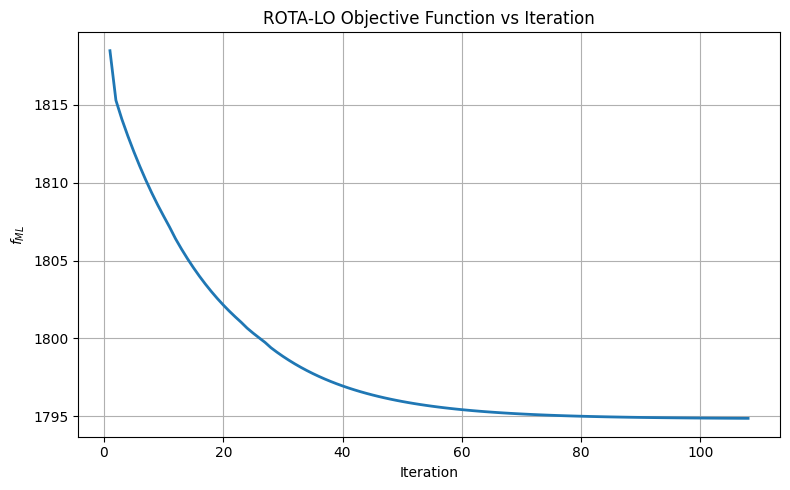

In [ ]:
iterations = [
    h["iteration"]
    for h in history
]

fml_values = [
    h["fml"]
    for h in history
]

plt.figure(figsize=(8, 5))

plt.plot(
    iterations,
    fml_values,
    linewidth=2
)

plt.xlabel("Iteration")
plt.ylabel(r"$f_{ML}$")
plt.title("ROTA­LO Objective Function vs Iteration")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    "fig2a_objective_vs_iterations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

RMSE vs outlier percentage

In [ ]:
outlier_percentages = [
    0.00,
    0.05,
    0.10,
    0.15,
    0.20
]

In [ ]:
rmse_outlier = []

for p in outlier_percentages:

    print(
        f"\nRunning outlier percentage = {p*100:.0f}%"
    )

    rmse, errors = monte_carlo_rmse(
        M=5,
        K=200,
        sigma2_true=1.0,
        outlier_percentage=p,
        MC=500,
        seed_start=10000 + int(p * 1000)
    )

    rmse_outlier.append(rmse)

    print(
        f"RMSE = {rmse:.6f} m"
    )


Running outlier percentage = 0%
Completed 50/500
Completed 100/500
Completed 150/500
Completed 200/500
Completed 250/500
Completed 300/500
Completed 350/500
Completed 400/500
Completed 450/500
Completed 500/500
RMSE = 8.233406 m

Running outlier percentage = 5%
Completed 50/500
Completed 100/500
Completed 150/500
Completed 200/500
Completed 250/500
Completed 300/500
Completed 350/500
Completed 400/500
Completed 450/500
Completed 500/500
RMSE = 7.766931 m

Running outlier percentage = 10%
Completed 50/500
Completed 100/500
Completed 150/500
Completed 200/500
Completed 250/500
Completed 300/500
Completed 350/500
Completed 400/500
Completed 450/500
Completed 500/500
RMSE = 8.845316 m

Running outlier percentage = 15%
Completed 50/500
Completed 100/500
Completed 150/500
Completed 200/500
Completed 250/500
Completed 300/500
Completed 350/500
Completed 400/500
Completed 450/500
Completed 500/500
RMSE = 8.877218 m

Running outlier percentage = 20%
Completed 50/500
Completed 100/500
Completed

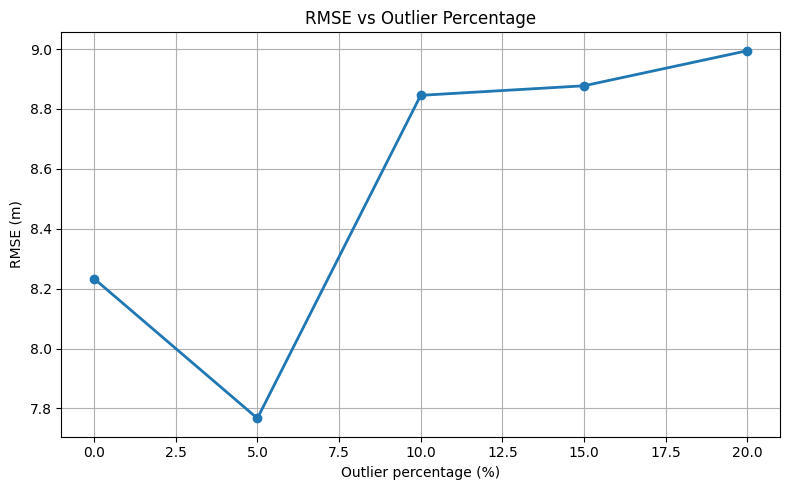

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    np.array(outlier_percentages) * 100,
    rmse_outlier,
    marker="o",
    linewidth=2
)

plt.xlabel("Outlier percentage (%)")
plt.ylabel("RMSE (m)")
plt.title("RMSE vs Outlier Percentage")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    "fig2b_rmse_vs_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

RMSE vs noise variance

In [ ]:
noise_variances = [
    0.1,
    0.5,
    1.0,
    2.0,
    5.0,
    10.0
]

Completed 20/200 trials
Completed 40/200 trials
Completed 60/200 trials
Completed 80/200 trials
Completed 100/200 trials
Completed 120/200 trials
Completed 140/200 trials
Completed 160/200 trials
Completed 180/200 trials
Completed 200/200 trials

========== RESULTS ==========
True target: [-5.  5. 10.]
Mean estimated position error: 0.45774967499842417
Monte-Carlo RMSE: 0.5865140996969502 m
Mean estimated noise variance: 0.35099835970333715
Mean detected outliers: 493.28
True outliers per trial: 200


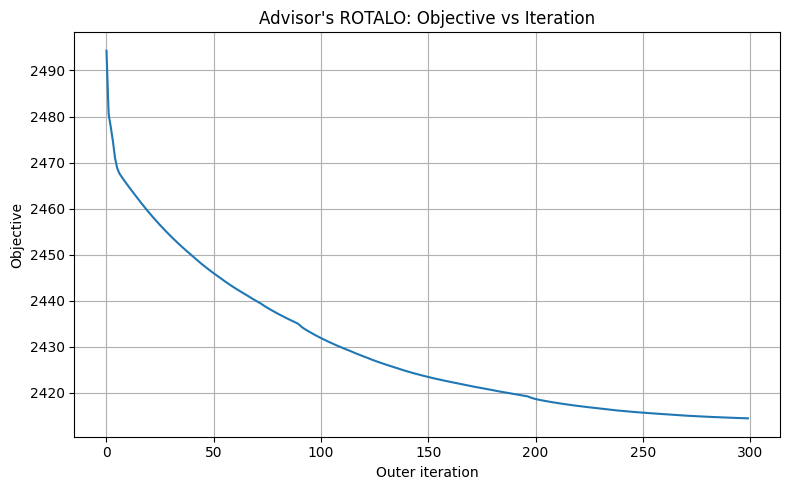

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

# ============================================================
# 1. SIMULATION PARAMETERS -- MATCHING ADVISOR'S MATLAB CODE
# ============================================================

np.random.seed(42)

samples = 200
MC = 200
sensors = 5
PER = 0.20

T = np.array([30.0, -15.0, 40.0])
u0 = np.array([-5.0, 5.0, 10.0])

d = 3
noise_db = 0
N_pow = 10.0 ** (noise_db / 10.0)

alpha = 0.05
max_outer_iter = 300
inner_tol = 1e-3
outlier_magnitude = 505.0

p = sensors
n = samples
total_measurements = p * n

# ============================================================
# 2. GENERATE RECEIVER POSITIONS
#    Same geometry as the advisor: sphere centered at u0
# ============================================================

r1 = np.random.randn(d, p)
rr = r1 / np.linalg.norm(r1, axis=0, keepdims=True)
r = rr * 50.0 + u0[:, None]  # Shape: (3, p)

# FDR thresholds in descending order
pvalue = alpha * np.arange(1, total_measurements + 1) / total_measurements
eta = chi2.ppf(1.0 - pvalue, df=1)


# ============================================================
# 3. BISTATIC RANGE
# ============================================================

def bistatic_ranges(x, T, r):
    tx_dist = np.linalg.norm(x - T)
    rx_dist = np.linalg.norm(x[:, None] - r, axis=0)
    return tx_dist + rx_dist


# ============================================================
# 4. GENERATE MEASUREMENTS AND ADD OUTLIERS
# ============================================================

def generate_measurements():
    # Ideal range for each receiver
    Y0 = bistatic_ranges(u0, T, r)

    # MATLAB: randn(1,p) * sqrtm(Q0)
    # Each row is one measurement snapshot.
    Y = (
        Y0[None, :]
        + np.random.randn(n, p) * np.sqrt(N_pow)
    ).T  # Shape: (p, n)

    Y_clean = Y.copy()
    true_outliers = np.zeros((p, n), dtype=bool)

    N_c = int(np.floor(PER * n))

    for i in range(p):
        # Choose N_c different measurement indices for receiver i
        indices = np.random.permutation(n)[:N_c]

        half = N_c // 2
        plus_indices = indices[:half]
        minus_indices = indices[half:]

        Y[i, plus_indices] += outlier_magnitude
        Y[i, minus_indices] -= outlier_magnitude

        true_outliers[i, indices] = True

    return Y, Y_clean, true_outliers


# ============================================================
# 5. MAD INITIALIZATION -- PORT OF MATLAB MAD()
#    sel = 1 means inlier; sel = 0 means suspected outlier
# ============================================================

def MAD(Y):
    p, n = Y.shape
    b = 1.4826

    med = np.median(Y, axis=1)
    deviations = np.abs(Y - med[:, None])
    med2 = b * np.median(deviations, axis=1)

    sel = np.ones((p, n), dtype=float)

    for i in range(p):
        # Numerical safeguard for zero MAD
        if med2[i] < 1e-12:
            sel[i, deviations[i] > 0] = 0.0
            continue

        normalized_deviation = deviations[i] / med2[i]
        sel[i, normalized_deviation >= 3.0] = 0.0

    return sel


# ============================================================
# 6. WLS INITIALIZATION -- PORT OF ADVISOR'S LINEAR SYSTEM
# ============================================================

def initialize_target_wls(Y, sel):
    p, n = Y.shape

    # MATLAB keeps only columns where every receiver is marked
    # as an inlier.
    valid_columns = np.all(sel == 1, axis=0)
    Y4 = Y[:, valid_columns]

    # Fallback if MAD marks every snapshot as containing an outlier.
    if Y4.shape[1] == 0:
        inlier_counts = np.sum(sel, axis=0)
        best_columns = np.flatnonzero(
            inlier_counts == np.max(inlier_counts)
        )
        Y4 = Y[:, best_columns]

    rows = []
    rhs = []

    for k in range(Y4.shape[1]):
        for i in range(p):
            y = Y4[i, k]

            # MATLAB:
            # dd = Y^2 + T'*T - r_i'*r_i
            # gg = 2 * [(T-r_i)', Y]
            row = 2.0 * np.append(T - r[:, i], y)
            value = y**2 + np.dot(T, T) - np.dot(r[:, i], r[:, i])

            rows.append(row)
            rhs.append(value)

    G = np.asarray(rows, dtype=float)
    h = np.asarray(rhs, dtype=float)

    # Equivalent least-squares solution to the linear system.
    # The first three components are the target estimate.
    theta, *_ = np.linalg.lstsq(G, h, rcond=None)
    u_init = theta[:d]

    # Initial variance calculation from the advisor's code
    predicted = bistatic_ranges(u_init, T, r)
    residual = Y4 - predicted[:, None]

    sigmaa = np.sum(residual**2) / (Y4.shape[1] * p)
    sigmaa = max(sigmaa, 1e-12)

    return u_init, sigmaa


# ============================================================
# 7. INNER UPDATE: TARGET POSITION AND NOISE VARIANCE
#    Port of MMupdateloc()
# ============================================================

def MMupdateloc(u_init, Y, sel, sigmaa):
    p, n = Y.shape
    eta_change = 1.0

    while eta_change > inner_tol:
        # Predicted range at current target
        tmp = bistatic_ranges(u_init, T, r)

        # MATLAB: A = residual.^2 / (n*p)
        residual = Y - tmp[:, None]
        A = residual**2 / (n * p)

        # Update noise variance using current inlier mask
        sigmaa = np.sum(sel * A)
        sigmaa = max(sigmaa, 1e-12)

        # Target update according to the paper's equation
        numerator = np.zeros(d)
        denominator = 0.0

        for k in range(n):
            for i in range(p):
                tx_vec = u_init - T
                rx_vec = u_init - r[:, i]

                tx_dist = max(np.linalg.norm(tx_vec), 1e-12)
                rx_dist = max(np.linalg.norm(rx_vec), 1e-12)

                s = tx_vec / tx_dist
                z = rx_vec / rx_dist

                h = tx_dist / rx_dist
                g = rx_dist / tx_dist

                weight = sel[i, k] / sigmaa

                c2 = Y[i, k] * (s + z)
                c3 = (1.0 + g) * T
                c4 = (1.0 + h) * r[:, i]
                c5 = 2.0 + h + g

                numerator += weight * (c2 + c3 + c4)
                denominator += weight * c5

        if denominator < 1e-12:
            break

        u_new = numerator / denominator

        # Relative change, matching the MATLAB inner stopping rule
        eta_change = (
            np.linalg.norm(u_init - u_new)
            / max(np.linalg.norm(u_init), 1e-12)
        )

        u_init = u_new

    return u_init, sigmaa


# ============================================================
# 8. COMPLETE ROTALO PROCEDURE
# ============================================================

def rotalo_advisor(Y):
    p, n = Y.shape

    # Initial inlier/outlier pattern
    sel = MAD(Y)

    # Initial target and noise variance
    u_init, sigmaa = initialize_target_wls(Y, sel)

    objective_history = []
    outlier_count_history = []

    # The advisor's outer loop runs for 300 iterations.
    # The MATLAB outer stopping condition is commented out.
    for iteration in range(max_outer_iter):
        u_previous = u_init.copy()

        # Update target and variance using current inlier pattern
        u_init, sigmaa = MMupdateloc(
            u_init, Y, sel, sigmaa
        )

        # Recompute residual test statistics
        tmp2 = bistatic_ranges(u_init, T, r)
        residual = Y - tmp2[:, None]
        Ts = residual**2 / max(sigmaa, 1e-12)

        # MATLAB Ts(:): column-major flattening
        Ts_vec = Ts.flatten(order="F")
        order = np.argsort(Ts_vec)[::-1]
        Tss = Ts_vec[order]

        # MATLAB:
        # sel2 = max(find(Tss > eta))
        exceed = np.flatnonzero(Tss > eta)

        # If no statistic exceeds its threshold, select no outliers.
        if len(exceed) == 0:
            sel2 = 0
        else:
            sel2 = exceed[-1] + 1

        # Start with all measurements classified as inliers.
        # Mark the largest sel2 statistics as outliers.
        sel_pat = np.ones(total_measurements, dtype=float)
        sel_pat[order[:sel2]] = 0.0

        # MATLAB reshape(..., p, n), using column-major ordering
        sel = sel_pat.reshape((p, n), order="F")

        nz = total_measurements - np.count_nonzero(sel)

        # Objective function as in the advisor's code
        objective = (
            total_measurements * np.log(max(sigmaa, 1e-12))
            + np.sum(sel * Ts)
            + np.sum(eta[:nz])
        )

        objective_history.append(objective)
        outlier_count_history.append(nz)

    return (
        u_init,
        sigmaa,
        sel,
        np.asarray(objective_history),
        np.asarray(outlier_count_history)
    )


# ============================================================
# 9. MONTE-CARLO EXPERIMENT
# ============================================================

squared_position_errors = []
estimated_variances = []
detected_outlier_counts = []
objective_histories = []

for mc in range(MC):
    Y, Y_clean, true_outliers = generate_measurements()

    x_hat, sigma2_hat, sel_hat, obj, n_out = rotalo_advisor(Y)

    # Euclidean squared position error
    position_error = np.linalg.norm(x_hat - u0)

    squared_position_errors.append(position_error**2)
    estimated_variances.append(sigma2_hat)
    detected_outlier_counts.append(n_out[-1])
    objective_histories.append(obj)

    if (mc + 1) % 20 == 0:
        print(f"Completed {mc + 1}/{MC} trials")

# RMSE across all Monte-Carlo trials
RMSE = np.sqrt(np.mean(squared_position_errors))

print("\n========== RESULTS ==========")
print("True target:", u0)
print("Mean estimated position error:", np.mean(
    np.sqrt(squared_position_errors)
))
print("Monte-Carlo RMSE:", RMSE, "m")
print("Mean estimated noise variance:", np.mean(estimated_variances))
print("Mean detected outliers:", np.mean(detected_outlier_counts))
print("True outliers per trial:", int(np.floor(PER * n) * p))


# ============================================================
# 10. PLOT OBJECTIVE FROM ONE TRIAL
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(objective_histories[0])
plt.xlabel("Outer iteration")
plt.ylabel("Objective")
plt.title("Advisor's ROTALO: Objective vs Iteration")
plt.grid(True)
plt.tight_layout()
plt.show()



Running outlier percentage: 0%
  Completed 50/200 trials
  Completed 100/200 trials
  Completed 150/200 trials
  Completed 200/200 trials
  RMSE: 0.1857 m
  Mean position error: 0.1585 m
  Mean detected outliers: 0.08

Running outlier percentage: 5%
  Completed 50/200 trials
  Completed 100/200 trials
  Completed 150/200 trials
  Completed 200/200 trials
  RMSE: 0.1963 m
  Mean position error: 0.1687 m
  Mean detected outliers: 54.26

Running outlier percentage: 10%
  Completed 50/200 trials
  Completed 100/200 trials
  Completed 150/200 trials
  Completed 200/200 trials
  RMSE: 0.2060 m
  Mean position error: 0.1752 m
  Mean detected outliers: 112.18

Running outlier percentage: 15%
  Completed 50/200 trials
  Completed 100/200 trials
  Completed 150/200 trials
  Completed 200/200 trials
  RMSE: 0.2618 m
  Mean position error: 0.2250 m
  Mean detected outliers: 176.46

Running outlier percentage: 20%
  Completed 50/200 trials
  Completed 100/200 trials
  Completed 150/200 trials
  Co

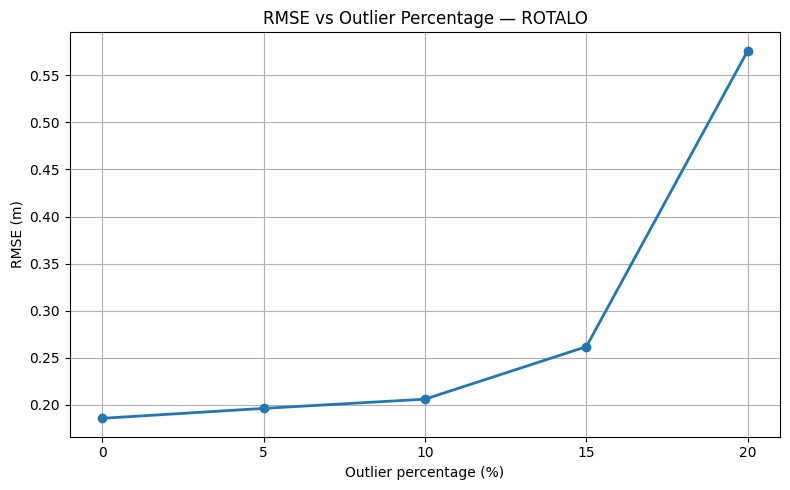

In [ ]:



import numpy as np
import matplotlib.pyplot as plt
import time

outlier_percentages = [0, 5, 10, 15, 20]
MC_exp = 200

rmse_results = []
mean_errors = []
mean_detected_outliers = []

start_time = time.time()


for percentage in outlier_percentages:

    PER = percentage / 100.0

    squared_errors = []
    position_errors = []
    detected_counts = []

    print(f"\nRunning outlier percentage: {percentage}%")

    for mc in range(MC_exp):

        Y, Y_clean, true_outliers = generate_measurements()

        x_hat, sigma2_hat, sel_hat, obj, n_out = rotalo_advisor(Y)

        error = np.linalg.norm(x_hat - u0)

        position_errors.append(error)
        squared_errors.append(error ** 2)

        detected_counts.append(np.sum(sel_hat == 0))

        if (mc + 1) % 50 == 0:
            print(f"  Completed {mc + 1}/{MC_exp} trials")

    rmse = np.sqrt(np.mean(squared_errors))

    rmse_results.append(rmse)
    mean_errors.append(np.mean(position_errors))
    mean_detected_outliers.append(np.mean(detected_counts))

    print(f"  RMSE: {rmse:.4f} m")
    print(f"  Mean position error: {np.mean(position_errors):.4f} m")
    print(f"  Mean detected outliers: {np.mean(detected_counts):.2f}")

print(f"\nTotal elapsed time: {(time.time() - start_time) / 60:.2f} minutes")


print("\n========== FINAL RESULTS ==========")
print("Outlier % | RMSE (m) | Mean error (m) | Detected outliers")

for i, percentage in enumerate(outlier_percentages):
    print(
        f"{percentage:8d}% | "
        f"{rmse_results[i]:8.4f} | "
        f"{mean_errors[i]:14.4f} | "
        f"{mean_detected_outliers[i]:17.2f}"
    )


plt.figure(figsize=(8, 5))
plt.plot(
    outlier_percentages,
    rmse_results,
    marker="o",
    linewidth=2
)

plt.xlabel("Outlier percentage (%)")
plt.ylabel("RMSE (m)")
plt.title("RMSE vs Outlier Percentage — ROTALO")
plt.xticks(outlier_percentages)
plt.grid(True)
plt.tight_layout()
plt.show()


Noise =  -3 dB | RMSE = 0.5187 m | Mean estimated variance = 0.1901
Noise =  -2 dB | RMSE = 0.5860 m | Mean estimated variance = 0.2104
Noise =  -1 dB | RMSE = 0.5835 m | Mean estimated variance = 0.2756
Noise =   0 dB | RMSE = 0.5829 m | Mean estimated variance = 0.3337
Noise =   1 dB | RMSE = 0.6058 m | Mean estimated variance = 0.4539
Noise =   2 dB | RMSE = 0.6083 m | Mean estimated variance = 0.5577
Noise =   3 dB | RMSE = 5.6666 m | Mean estimated variance = 0.7774
Noise =   4 dB | RMSE = 16.7295 m | Mean estimated variance = 1.3584
Noise =   5 dB | RMSE = 26.9891 m | Mean estimated variance = 1.9010
Noise =   6 dB | RMSE = 28.5901 m | Mean estimated variance = 2.1270
Noise =   7 dB | RMSE = 28.7984 m | Mean estimated variance = 2.5845
Noise =   8 dB | RMSE = 28.9834 m | Mean estimated variance = 3.0541
Noise =   9 dB | RMSE = 29.1086 m | Mean estimated variance = 3.3917
Noise =  10 dB | RMSE = 28.9530 m | Mean estimated variance = 4.6617


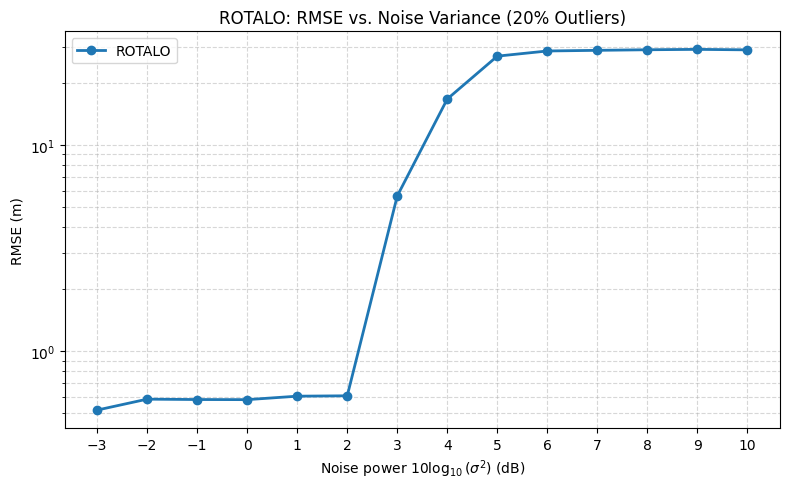

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

MC = 200
PER = 0.20
alpha = 0.05

u0 = np.array([-5.0, 5.0, 10.0])

noise_levels_db = np.arange(-3, 11, 1)

rmse_results = []
mean_variance_results = []

for db in noise_levels_db:
    noise_db = float(db)
    N_pow = 10.0 ** (noise_db / 10.0)

    errors_squared = []
    estimated_variances = []

    for trial in range(MC):
        Y, Y_clean, true_outliers = generate_measurements()
        u_est, sigma_est, sel, objective_history, outlier_history = (
            rotalo_advisor(Y)
        )

        error = np.linalg.norm(u_est - u0)
        errors_squared.append(error ** 2)
        estimated_variances.append(sigma_est)

    rmse = np.sqrt(np.mean(errors_squared))
    mean_sigma = np.mean(estimated_variances)

    rmse_results.append(rmse)
    mean_variance_results.append(mean_sigma)

    print(
        f"Noise = {db:>3} dB | "
        f"RMSE = {rmse:.4f} m | "
        f"Mean estimated variance = {mean_sigma:.4f}"
    )

rmse_results = np.array(rmse_results)
mean_variance_results = np.array(mean_variance_results)

plt.figure(figsize=(8, 5))
plt.semilogy(
    noise_levels_db,
    rmse_results,
    marker="o",
    linewidth=2,
    label="ROTALO"
)

plt.xlabel(r"Noise power $10\log_{10}(\sigma^2)$ (dB)")
plt.ylabel("RMSE (m)")
plt.title("ROTALO: RMSE vs. Noise Variance (20% Outliers)")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.xticks(noise_levels_db)
plt.legend()
plt.tight_layout()
plt.savefig("rotalo_rmse_vs_noise.png", dpi=300)
plt.show()
